# DSC PJATK Catalogue Quality Challenge — EDA

Eksploracja danych treningowych, z której wynikły dwie zmiany w modelu:
1. odczyt liczby sztuk z tekstu (`main_items`, porównanie #1),
2. cena i waga za sztukę względem typowej dla produktu (`OffTypical`, porównanie #2).

Target służy tu tylko do sprawdzania hipotez na train. Nic z tego notebooka nie trafia do modelu jako dane.

Dwa wykresy opowiadają tę historię: **Wykres 1** (liczba sztuk, krok 2) i **Wykres 2** (cena i waga względem produktu, krok 3).

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

pd.set_option('display.max_colwidth', None)
local = Path('data/public')
data_dir = local if (local / 'train.csv').exists() else next(Path('/kaggle/input').rglob('train.csv')).parent
train = pd.read_csv(data_dir / 'train.csv')
desc = train.description.fillna('').str.lower()
print(train.shape)
train.head()

(16000, 11)


,id,seller_id,title,description,declared_category,brand,condition,price_pln,shipping_weight_kg,pack_size,target
0,OFR_191714271,SEL_7523257,recording mic support — pack of one — Mira A513,Pack of one main items. Microphone stand by Mira. Variant: standard. For listening at home or at a desk. Packed for delivery.,audio,Mira,used,70.43,5.233,1.0,1
1,OFR_517640949,SEL_2053194,in-ear cable headphones — quantity 2 — Noro E315,Included main items: 2. Wired earbuds by Noro. Variant: compact. For listening at home or at a desk. Check dimensions before purchase.,computers,Noro,used,28.95,0.119,2.0,1
2,OFR_634805877,SEL_8620752,Tenso digital food balance / standard / quantity 1,Included main items: 1. Kitchen scale by Tenso. Variant: standard. For food preparation or kitchen storage. Packed for delivery.,kitchen,Tenso,new,62.05,0.412,1.0,0
3,OFR_643990737,SEL_8396386,litter scoop — five main items — Velo E263,Cat tray cleaning shovel by Velto. Variant: standard. Five individually boxed main items. Choose a size appropriate for your pet. Packed for delivery.,pets,Velto,used,102.26,0.499,5.0,0
4,OFR_260742748,SEL_5029882,LAPTOP SLEEVE — PACK OF FIVE — ASTER F219,Variant: standard. Also includes 3 pcs of free accessory pieces; these do not count as main items. Notebook protective pouch by Aster. Pack of five main items. Check compatibility with your device. Check dimensions before purchase.,computers,Aster,used,144.84,0.856,5.0,0


## Krok 1: wskazówka „liczba sztuk” w baseline

Baseline bierze pierwszą liczbę przed „pcs” i porównuje ją z `pack_size`. Komentarz organizatorów ostrzega przed gratisami i liczbami zapisanymi słowami.

In [2]:
has_pcs = desc.str.contains(r'\d+\s*pcs')
has_free = desc.str.contains('free accessor')
print('Opisy z "pcs":', has_pcs.sum())
print('...w tym z darmowymi akcesoriami:', (has_pcs & has_free).sum())

Opisy z "pcs": 5735
...w tym z darmowymi akcesoriami: 3865


In [3]:
first = pd.to_numeric(desc.str.extract(r'(\d+)\s*pcs', expand=False), errors='coerce')
wrong = first.notna() & train.pack_size.notna() & (first != train.pack_size)
print('Liczba przed "pcs" inna niż pack_size:', wrong.sum())
print('...z tego w opisach z gratisami:', (wrong & has_free).sum())
print(train.loc[wrong & has_free, ['description', 'pack_size']].head(3).to_string())

Liczba przed "pcs" inna niż pack_size: 2587
...z tego w opisach z gratisami: 2537
                                                                                                                                                                                                                                description  pack_size
4   Variant: standard. Also includes 3 pcs of free accessory pieces; these do not count as main items. Notebook protective pouch by Aster. Pack of five main items. Check compatibility with your device. Check dimensions before purchase.        5.0
5                              Variant: standard. Also includes 3 pcs of free accessory pieces; these do not count as main items. Bluetooth speaker by Tenso. Pack of two main items. Designed for everyday sound use. Packed for delivery.        2.0
10                     Variant: standard. Also includes 1 pcs of free accessory pieces; these do not count as main items. Hair shampoo by Mira. Pack of three main items. Read th

In [4]:
words = r'\b(?:one|two|three|four|five)\b'
has_word = desc.str.contains(words)
print('Opisy z liczbą zapisaną słowem:', has_word.sum())
print('...w tym bez "pcs" (baseline nic tu nie odczyta):', (has_word & ~has_pcs).sum())

Opisy z liczbą zapisaną słowem: 5265
...w tym bez "pcs" (baseline nic tu nie odczyta): 3979


**Wniosek:** 98% niezgodności to oferty z gratisami (baseline czyta liczbę gratisów), a 3979 ofert ma liczbę tylko słowem.

Hipoteza odrzucona: czy brak marki w tytule oznacza złą ofertę?

In [5]:
brand = train.brand.fillna('').str.lower()
title = train.title.fillna('').str.lower()
train['marka_w_tytule'] = [b in t for b, t in zip(brand, title)]
train[(brand != '') & (title != '')].groupby('marka_w_tytule').target.agg(['count', 'mean'])

,count,mean
marka_w_tytule,,
False,145,0.200000
True,14471,0.171377


## Krok 2: jakie formuły ilości występują w opisach

Zamiana każdej liczby na `#` sprawia, że zdania z różnymi liczbami wyglądają tak samo; `value_counts` pokazuje listę szablonów.

In [6]:
num = r'\b(?:\d+|one|two|three|four|five)\b'
zdania = desc.str.split(r'[.;]\s*', regex=True).explode()
z_liczba = zdania[zdania.str.contains(num)]
szablony = z_liczba.str.replace(num, '#', regex=True)
szablony.value_counts().head(15)

description
also includes # pcs of free accessory pieces    3865
pack of # main items                            2869
bundle quantity: # units                        2609
package contains # pcs                          2544
included main items: #                          2484
sold as a #-pack                                2431
# individually boxed main items                 2383
#-string small guitar by tenso                     8
#-string small guitar by mira                      6
#-string small guitar by velto                     2
#-string small guitar by noro                      2
#-string small guitar by aster                     1
Name: count, dtype: int64

In [7]:
WORDS = {'one': '1', 'two': '2', 'three': '3', 'four': '4', 'five': '5'}
QTY = (r'(?:pack of|contains|main items:|quantity:?)\s*(\d+)'
       r'|(\d+)\s*(?:-pack|units|pcs|main items|individually)')


def main_items(text):
    text = text.lower()
    text = re.sub(r'also includes \w+ pcs of free accessory pieces', ' ', text)
    for word, digit in WORDS.items():
        text = re.sub(r'\b' + word + r'\b', digit, text)
    found = re.search(QTY, text)
    if found is None:
        return np.nan
    return float(found.group(1) or found.group(2))


print(main_items('Also includes 3 pcs of free accessory pieces; these do not count as main items. Pack of five main items.'))
print(main_items('Included main items: 2'))
print(main_items('Sold as a 3-pack'))
print(main_items('6-string small guitar by Mira'))

5.0
2.0
3.0
nan


In [8]:
text = train.title.fillna('') + ' ' + train.description.fillna('')
new_pack = text.apply(main_items)
diff = (new_pack - train.pack_size).abs()
print('Odczytano liczbę w', new_pack.notna().sum(), 'z', len(train), 'ofert')
print(pd.crosstab(diff > 0, train.target))

Odczytano liczbę w 15951 z 16000 ofert
target      0     1
row_0              
False   13279  2330
True        0   391


### Wykres 1: kiedy alarm „liczba sztuk się nie zgadza” trafia

Porównuję dwa odczyty liczby sztuk z tekstu: stary z baseline (pierwsza liczba przed „pcs”) i nowy `main_items`.
Słupki pokazują, ile dobrych i ile złych ofert dostaje alarm „odczyt ≠ `pack_size`”.

        Stary licznik „pcs” (baseline)  main_items (exp1)
target                                                   
0                                 2088                  0
1                                  499                391


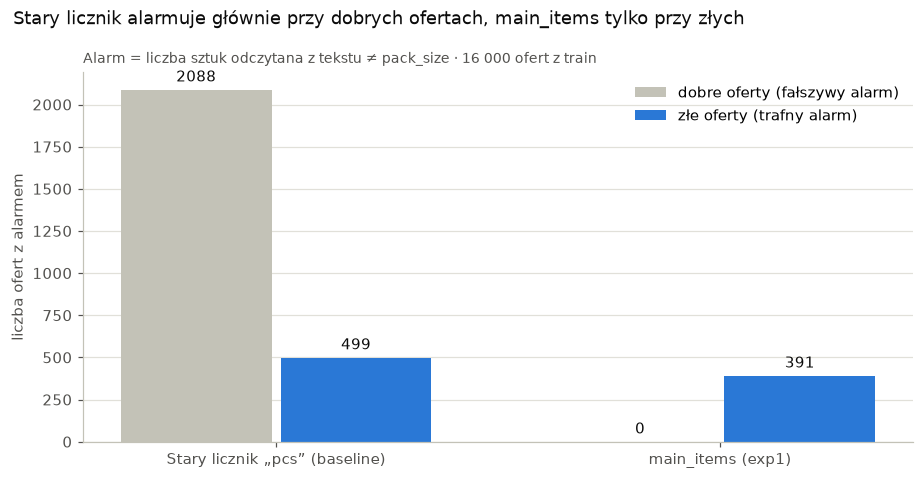

In [9]:
import matplotlib.pyplot as plt

# Kolory: szary dla tła porównania, niebieski dla tego, o czym jest wykres.
BLUE, GREY, DARK_GREY, INK, MUTED, GRID = '#2a78d6', '#c3c2b7', '#898781', '#0b0b0b', '#52514e', '#e1e0d9'
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': GREY, 'axes.labelcolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'figure.dpi': 110})

# wrong: stary odczyt (komórka z „pcs” wyżej), diff: nowy odczyt main_items (komórka wyżej)
alarm = pd.DataFrame({'Stary licznik „pcs” (baseline)': train.target[wrong].value_counts(),
                      'main_items (exp1)': train.target[diff > 0].value_counts()})
alarm = alarm.reindex([0, 1]).fillna(0).astype(int)   # wiersz 0 = dobre oferty, 1 = złe
print(alarm)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
x = np.arange(len(alarm.columns))
for shift, target, color, name in [(-0.18, 0, GREY, 'dobre oferty (fałszywy alarm)'),
                                   (0.18, 1, BLUE, 'złe oferty (trafny alarm)')]:
    bars = ax.bar(x + shift, alarm.loc[target], width=0.34, color=color, label=name)
    ax.bar_label(bars, padding=3, color=INK)
ax.set_xticks(x, alarm.columns)
ax.set_ylabel('liczba ofert z alarmem')
ax.grid(axis='y', color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.suptitle('Stary licznik alarmuje głównie przy dobrych ofertach, main_items tylko przy złych',
             x=0.02, ha='left', fontsize=12, color=INK)
ax.set_title('Alarm = liczba sztuk odczytana z tekstu ≠ pack_size · 16 000 ofert z train',
             loc='left', fontsize=9, color=MUTED)
plt.tight_layout()
plt.show()

**Co widać:** stary licznik daje alarm w ponad 2 000 dobrych ofert (czyta liczbę gratisów), więc alarm prawie nic nie znaczy.
Po zmianie alarm zapala się tylko przy złych ofertach. Stąd porównanie #1 (`main_items`).

**Wniosek:** nowy odczyt różni się od `pack_size` w 0 dobrych i 391 złych ofertach (stary: 2088 dobrych i 499 złych).

## Krok 3: cena i waga względem typowej dla produktu

Nazwa produktu z opisu („Microphone stand by Mira”), potem odległość ceny/wagi za sztukę od mediany produktu (w logarytmach, czyli „ile razy”).
Tu mediany liczone są z całego train tylko do eksploracji; w modelu liczy je `OffTypical.fit` na foldzie treningowym.

In [10]:
train['product'] = desc.str.extract(r'(?:^|\.\s*)([a-z][a-z \-]+?) by \w+', expand=False)
print('Rozpoznany produkt w', train['product'].notna().sum(), 'z', len(train), 'ofert, różnych produktów:', train['product'].nunique())
print(train.loc[0, ['title', 'product', 'shipping_weight_kg', 'target']])

Rozpoznany produkt w 15320 z 16000 ofert, różnych produktów: 180
title                 recording mic support — pack of one — Mira A513
product                                              microphone stand
shipping_weight_kg                                              5.233
target                                                              1
Name: 0, dtype: object


In [11]:
for col in ['shipping_weight_kg', 'price_pln']:
    value = np.log(train[col] / train.pack_size.clip(lower=1))
    typical = value.groupby(train['product']).transform('median')
    off = (value - typical).abs()
    ok = off.notna()
    print(col)
    print(train.groupby(pd.cut(off, [0, 0.3, 0.5, 0.7, 1, 10], include_lowest=True), observed=True).target.agg(['count', 'mean']).round(3))
    print('AUC samej wartości na sztukę:', round(roc_auc_score(train.target[ok], value[ok]), 4))
    print('AUC odległości od typowej:   ', round(roc_auc_score(train.target[ok], off[ok]), 4))
    print()

shipping_weight_kg
               count   mean
(-0.001, 0.3]  10198  0.111
(0.3, 0.5]      2308  0.133
(0.5, 0.7]       638  0.281
(0.7, 1.0]       259  0.838
(1.0, 10.0]      539  1.000
AUC samej wartości na sztukę: 0.4682
AUC odległości od typowej:    0.6922

price_pln
               count   mean
(-0.001, 0.3]   7511  0.106
(0.3, 0.5]      3208  0.127
(0.5, 0.7]      1702  0.153
(0.7, 1.0]      1014  0.305
(1.0, 10.0]      825  0.779
AUC samej wartości na sztukę: 0.4731
AUC odległości od typowej:    0.6971



**Wniosek:** sama waga i cena na sztukę mają AUC ok. 0,47 (jak rzut monetą), bo „drogo” i „ciężko” zależą od produktu.
Odległość od mediany produktu daje 0,69 (waga) i 0,70 (cena); przy odległości > 1 (ok. 2,7×) złych jest 100% (waga) i 78% (cena).

### Wykres 2: sama cena nic nie mówi, odległość od typowej dla produktu – bardzo dużo

Lewy panel: oferty podzielone na 5 równych grup według samej ceny (i wagi) za sztukę.
Prawy panel: te same oferty według tego, ile razy cena (i waga) za sztukę odbiega od mediany tego samego produktu.
Słupek = odsetek złych ofert w grupie; przerywana linia = średnia w całym train.

     cena za sztukę  waga za sztukę
0.0            23.6            22.7
1.0            13.7            14.9
2.0            13.9            13.2
3.0            13.8            16.2
4.0            19.5            17.6

            cena za sztukę  waga za sztukę
do 1,35×              10.6            11.1
1,35–1,65×            12.7            13.3
1,65–2×               15.3            28.1
2–2,7×                30.5            83.8
ponad 2,7×            77.9           100.0


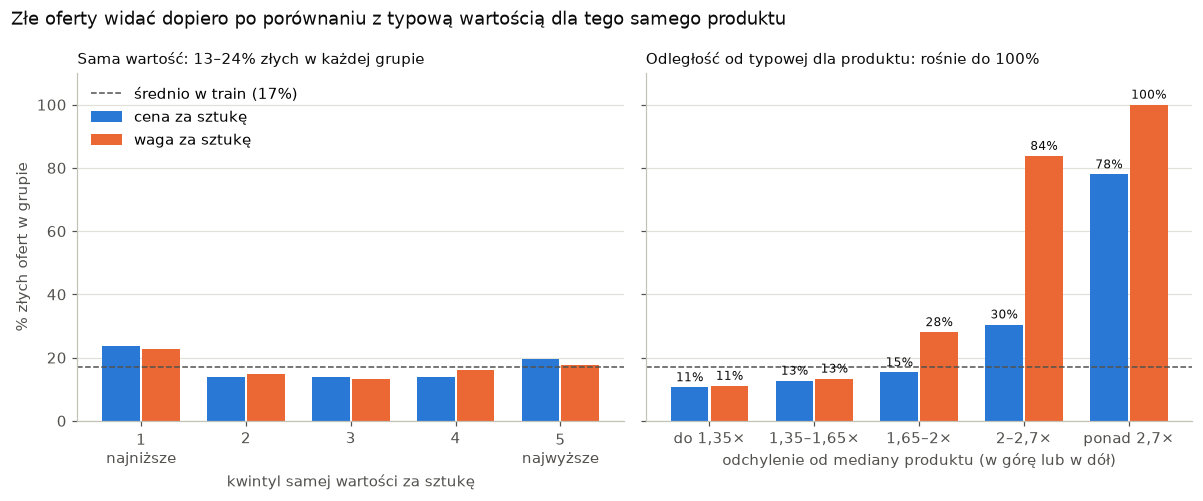

In [12]:
bins = [0, 0.3, 0.5, 0.7, 1, 10]                        # odległość w logarytmach
names = ['do 1,35×', '1,35–1,65×', '1,65–2×', '2–2,7×', 'ponad 2,7×']   # to samo jako „ile razy”
raw, dist = {}, {}
for col, name in [('price_pln', 'cena za sztukę'), ('shipping_weight_kg', 'waga za sztukę')]:
    value = np.log(train[col] / train.pack_size.clip(lower=1))
    off = (value - value.groupby(train['product']).transform('median')).abs()
    raw[name] = train.target.groupby(pd.qcut(value, 5, labels=False)).mean() * 100
    dist[name] = train.target.groupby(pd.cut(off, bins, labels=names, include_lowest=True), observed=True).mean() * 100
raw, dist = pd.DataFrame(raw), pd.DataFrame(dist)
average = train.target.mean() * 100
print(raw.round(1), dist.round(1), sep='\n\n')

ORANGE = '#eb6834'
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
panels = [(axes[0], raw, ['1\nnajniższe', '2', '3', '4', '5\nnajwyższe'], 'kwintyl samej wartości za sztukę',
           f'Sama wartość: {raw.min().min():.0f}–{raw.max().max():.0f}% złych w każdej grupie'),
          (axes[1], dist, names, 'odchylenie od mediany produktu (w górę lub w dół)',
           f'Odległość od typowej dla produktu: rośnie do {dist.max().max():.0f}%')]
for ax, table, labels, xlabel, title in panels:
    x = np.arange(len(table))
    for shift, col, color in [(-0.19, 'cena za sztukę', BLUE), (0.19, 'waga za sztukę', ORANGE)]:
        bars = ax.bar(x + shift, table[col], width=0.36, color=color, label=col)
        if table is dist:
            ax.bar_label(bars, fmt='%.0f%%', padding=2, fontsize=8, color=INK)
    ax.axhline(average, color=MUTED, linestyle='--', linewidth=1, label=f'średnio w train ({average:.0f}%)')
    ax.set_xticks(x, labels)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc='left', fontsize=10, color=INK)
    ax.grid(axis='y', color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel('% złych ofert w grupie')
axes[0].set_ylim(0, 110)
axes[0].legend(frameon=False, loc='upper left')
fig.suptitle('Złe oferty widać dopiero po porównaniu z typową wartością dla tego samego produktu',
             x=0.01, ha='left', fontsize=12, color=INK)
plt.tight_layout()
plt.show()

**Co widać:** w lewym panelu każda grupa ma 13–24% złych ofert, blisko średniej 17% – sama cena czy waga prawie nie odróżnia złych ofert, bo „drogo” zależy od produktu.
W prawym panelu odsetek złych rośnie z odległością od mediany produktu, aż do 78% (cena) i 100% (waga) przy odchyleniu ponad 2,7×.
Stąd porównanie #2 (`OffTypical`). W modelu mediany liczy `OffTypical.fit` tylko na foldzie treningowym; tutaj, w eksploracji, z całego train.